# Coherence scanning interferometry

A **coherence scanning interferometer** (CSI), also called a white-light
interferometer, is the workhorse of surface metrology in precision optics,
semiconductor and MEMS fabs: a microscope with an interference objective
and a broadband source that measures the height of every camera pixel to
a nanometre or better, over steps of millimetres. The objective is scanned
along its axis, and every pixel records a **correlogram**, fringes that
appear only where the paths to the reference mirror and to the surface
agree within the coherence length of the light. The position of the
fringe envelope gives the height without the $2\pi$ ambiguity of a laser
interferometer, the phase of the fringes refines it.

The physics is that of time-domain OCT in notebook 82 (optical coherence
tomography), with two differences: the sample is a surface instead of a
volume, and the objective has a large numerical aperture, which changes
the fringe period. This notebook uses the `csi` module:

1. the correlogram of a mirror for an LED and a white LED, and its
   coherence length,
2. heights from the envelope and from the phase (frequency domain
   analysis), their noise and the fringe order,
3. the numerical aperture and the obliquity factor,
4. a surface map,
5. dissimilar materials: the phase on reflection of metals,
6. transparent films: the thin film effect and film thickness,
7. the batwing artefact at steps.

Lengths are in µm.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import csi, sketch
from pyoptics import ellipsometry as el
from pyoptics.oct import axial_resolution

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

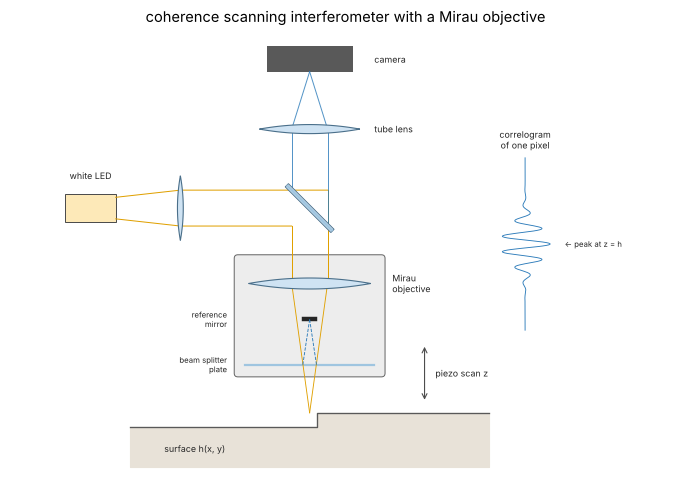

In [2]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
sketch.metrology_layout(ax, "csi", title="coherence scanning interferometer with a Mirau objective")
plt.show()

## 1. The correlogram

A Mirau objective carries a small reference mirror on its front lens and
a beam splitter plate between lens and sample; the reference path ends at
the focal plane. When the objective is at the scan position $z$ and the
surface at the height $h$, a plane wave in the pupil at the angle
$\theta$ and with the wavenumber $k$ has the path difference
$2(h - z)\cos\theta$. The camera pixel sees

$$
I(z) = \sum_k S(k) \sum_\theta w(\theta)\left[|r_R|^2 + |r_S|^2
  + 2\,\mathrm{Re}\left(r_R^* r_S\, e^{2ik\cos\theta\,(h - z)}\right)\right],
$$

summed over the source spectrum $S(k)$ and the illuminated pupil
(`csi.correlogram()`). For a Gaussian spectrum of the FWHM
$\Delta\lambda$ the envelope has the FWHM
$2\ln 2\,\lambda_0^2/(\pi\Delta\lambda)$, the axial resolution of OCT
(`csi.coherence_length()`, `oct.axial_resolution()`). A white LED is a
blue line plus a broad phosphor band: its envelope is narrow, but the two
bands beat and leave side lobes.

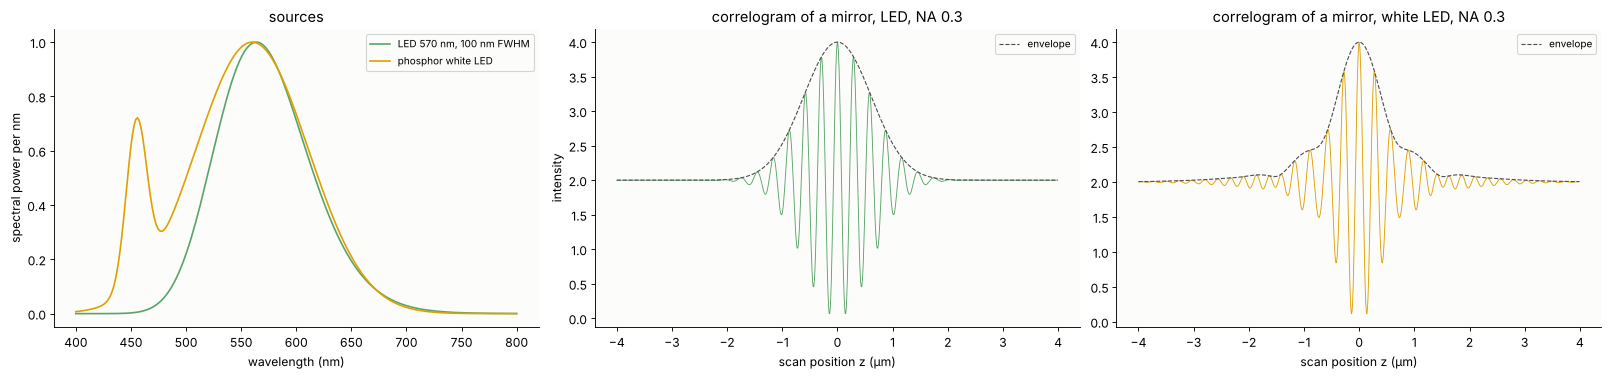

LED       : envelope FWHM 1.44 um
white LED : envelope FWHM 0.94 um
Gaussian formula for 570/100 nm: 1.43 um (= oct.axial_resolution 1.43 um)


In [3]:
k = np.linspace(2*np.pi/0.80, 2*np.pi/0.40, 160)
S_led = csi.led_spectrum(k, 0.57, 0.10)
S_white = csi.white_led_spectrum(k)
z = np.arange(-4, 4, 0.01)
fig, axs = plt.subplots(1, 3, figsize=(20, 4.6), layout="constrained")
wl = 2*np.pi/k
axs[0].plot(wl*1e3, S_led*k**2/np.max(S_led*k**2), color=GREEN, label="LED 570 nm, 100 nm FWHM")
axs[0].plot(wl*1e3, S_white*k**2/np.max(S_white*k**2), color=ORANGE, label="phosphor white LED")
axs[0].set_xlabel("wavelength (nm)")
axs[0].set_ylabel("spectral power per nm")
axs[0].legend(fontsize=9)
axs[0].set_title("sources")
for ax, S, c, name in ((axs[1], S_led, GREEN, "LED"), (axs[2], S_white, ORANGE, "white LED")):
    I = csi.correlogram(z, k, S, 0.0, NA=0.3)
    ax.plot(z, I, color=c, lw=0.8)
    ax.plot(z, I.mean() + csi.envelope(I), color="0.3", lw=1.0, ls="--", label="envelope")
    ax.set_xlabel("scan position z (µm)")
    ax.set_title("correlogram of a mirror, " + name + ", NA 0.3")
    ax.legend(fontsize=9)
axs[1].set_ylabel("intensity")
plt.show()
for S, name in ((S_led, "LED"), (S_white, "white LED")):
    env = csi.envelope(csi.correlogram(z, k, S, 0.0, NA=0.3))
    above = z[env > env.max()/2]
    print("{:10s}: envelope FWHM {:.2f} um".format(name, above[-1] - above[0]))
print("Gaussian formula for 570/100 nm: {:.2f} um (= oct.axial_resolution {:.2f} um)".format(
    csi.coherence_length(0.57, 0.10), axial_resolution(0.57, 0.10)))

The envelope of the LED is 1.4 µm wide, as the formula says: only within
about a micrometre of the focus do fringes appear. The white LED has a
narrower envelope, but the beat of its two bands repeats it at a
distance of about $\lambda_1\lambda_2/(2|\lambda_1 - \lambda_2|)$,
small side lobes that an envelope detector must not mistake for the
surface. Commercial instruments use LEDs of a few tens to hundreds of
nanometres or filtered halogen lamps for that reason.

## 2. Heights from the envelope and from the phase

**Envelope detection** finds the peak of the envelope, here as the
centroid of the squared envelope or a parabola through its logarithm
(`csi.envelope_peak()`). **Frequency domain analysis** (FDA, de Groot and
Deck 1995) Fourier transforms the correlogram instead. A surface at the
height $h$ contributes the phase

$$\phi(K) = K h - \arg r_S$$

at the spatial frequency $K = 2k\cos\theta$ (minus, because a higher
surface has a shorter path and, in the pyoptics convention, a smaller
phase). A straight line through
$\phi(K)$ gives the **coherence height** from its slope and, at the mean
frequency $K_0$, the **phase height** $\phi(K_0)/K_0$, which is
unambiguous once the coherence height selects its fringe order
(`csi.fda()`). The phase height uses all fringes at once: it is far less
noisy than the envelope. The constant part of $\arg r_S$, the **phase
gap**, must be known for the order decision: glass reflects with
$r_S = -0.2$, a phase of $\pi$ against the reference, which is passed
to `fda()` as `phase_gap=np.pi` (instruments calibrate it).

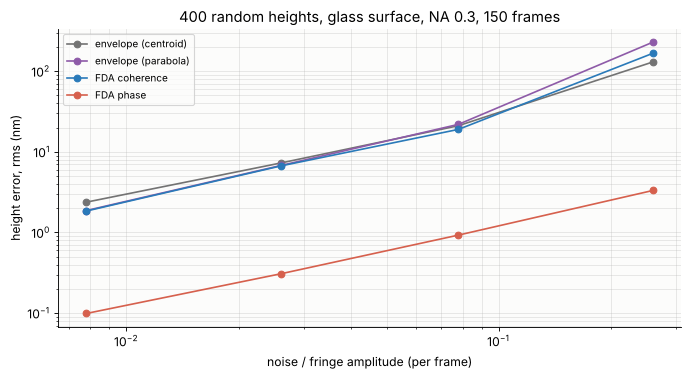

noise 0.008: centroid    2.4 nm, parabola    1.9 nm, FDA coherence   1.8 nm, FDA phase  0.10 nm, fringe order errors 0.0%
noise 0.026: centroid    7.3 nm, parabola    6.8 nm, FDA coherence   6.7 nm, FDA phase  0.31 nm, fringe order errors 0.0%
noise 0.078: centroid   21.1 nm, parabola   21.9 nm, FDA coherence  19.0 nm, FDA phase  0.93 nm, fringe order errors 0.0%
noise 0.260: centroid  130.5 nm, parabola  229.8 nm, FDA coherence 167.2 nm, FDA phase  3.32 nm, fringe order errors 17.2%


In [4]:
rng = np.random.default_rng(1)
k_m = k[::2]
S_m = S_led[::2]
z_m = np.arange(-3, 3, 0.04)              # 40 nm steps, about 7 frames per fringe
K_band = (2*k_m.min()*0.9, 2*k_m.max()*1.02)
noise_levels = np.array([0.003, 0.01, 0.03, 0.1])
h_true = rng.uniform(-0.5, 0.5, 400)
I0 = csi.correlogram(z_m, k_m, S_m, h_true, NA=0.3, reflectance=-0.2)
res = {"envelope (centroid)": [], "envelope (parabola)": [], "FDA coherence": [], "FDA phase": []}
order_err = []
for sigma in noise_levels:
    In = I0 + sigma*rng.standard_normal(I0.shape)
    hc, hp, K0 = csi.fda(z_m, In, K_band, phase_gap=np.pi)
    res["envelope (centroid)"].append(np.std(csi.envelope_peak(z_m, In) - h_true))
    res["envelope (parabola)"].append(np.std(csi.envelope_peak(z_m, In, "parabola") - h_true))
    res["FDA coherence"].append(np.std(hc - h_true))
    e = hp - h_true
    jumps = np.abs(e) > np.pi/np.mean(K0)/2
    order_err.append(jumps.mean())
    res["FDA phase"].append(np.std(e[~jumps]))
fringe_contrast = 2*0.2/(1 + 0.04)          # glass: r_S = -0.2 against r_R = 1
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
for (name, v), c in zip(res.items(), (GREY, PURPLE, BLUE, RED)):
    ax.loglog(noise_levels/fringe_contrast, np.array(v)*1e3, "o-", color=c, label=name)
ax.set_xlabel("noise / fringe amplitude (per frame)")
ax.set_ylabel("height error, rms (nm)")
ax.set_title("400 random heights, glass surface, NA 0.3, 150 frames")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=9)
plt.show()
for s, a, b, c, d, o in zip(noise_levels/fringe_contrast, *res.values(), order_err):
    print("noise {:5.3f}: centroid {:6.1f} nm, parabola {:6.1f} nm, FDA coherence {:5.1f} nm, "
          "FDA phase {:5.2f} nm, fringe order errors {:.1%}".format(s, a*1e3, b*1e3, c*1e3, d*1e3, o))

The phase height is about twenty times better than any envelope
estimate: a correlogram with 3 % noise per frame still gives a
nanometre. Its weak point is the fringe order. It is chosen by the
coherence height, so the coherence height must be right to better than a
quarter of the mean wavelength, $\pi/K_0 = \lambda/4 \approx 140$ nm
here; with very noisy data (the last point) some pixels jump by a whole
fringe, $\lambda/2$, the "2π errors" of CSI. De Groot et al. (2002)
discuss how to make the order decision robust. The noise here is white;
real instruments also suffer from scan errors (vibration, nonlinear
piezos), which shift the frames and affect the phase
more than the envelope.

## 3. Numerical aperture and the obliquity factor

Light that reaches the surface at the angle $\theta$ sees the path
difference $2(h - z)\cos\theta$: the fringes of the oblique rays are
longer. For a uniformly filled pupil of $\mathrm{NA} = \sin\alpha$ the
mean is the obliquity factor (Sheppard and Larkin 1995)

$$
\langle\cos\theta\rangle = \frac{2(1 - \cos^3\alpha)}{3\sin^2\alpha}
  \approx 1 - \frac{\mathrm{NA}^2}{4},
$$

and the fringe period is $\lambda/(2\langle\cos\theta\rangle)$
(`csi.obliquity_factor()`). The envelope still peaks at $z = h$. A phase
converted to height with the nominal wavelength, as in phase shifting
interferometry, is too small by $\langle\cos\theta\rangle$: 7 % at NA 0.5,
25 % at NA 0.9. FDA measures the fringe frequency itself and needs no
correction.

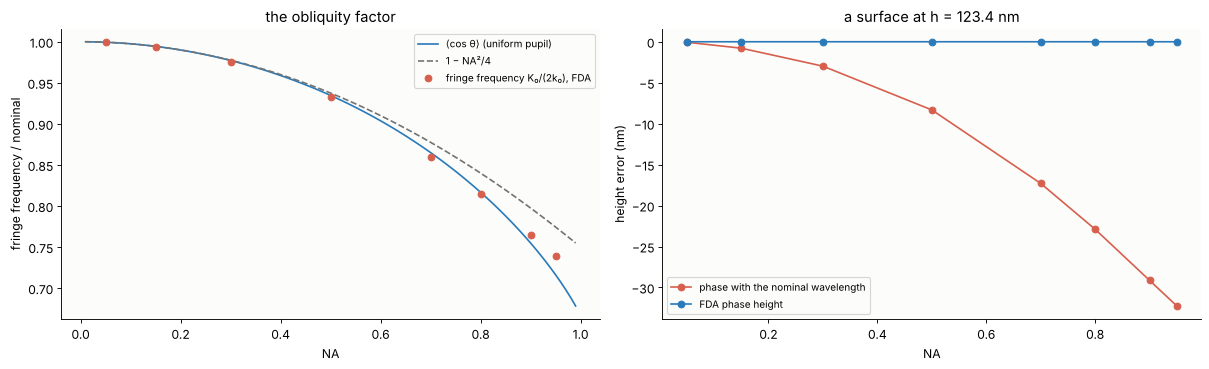

In [5]:
NAs = np.array([0.05, 0.15, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95])
k0 = np.sum(S_m*k_m)/np.sum(S_m)
K0s, h_nominal, h_fda = [], [], []
h_test = 0.1234
for NA in NAs:
    I = csi.correlogram(z_m, k_m, S_m, h_test, NA=NA, n_pupil=24)
    hc, hp, K0 = csi.fda(z_m, I, (2*k_m.min()*np.sqrt(1 - NA**2)*0.85, 2*k_m.max()*1.02))
    F = csi.fourier_signal(z_m, I, [K0])            # the phase of the fringes ...
    K0s.append(K0)
    h_nominal.append(np.angle(F[0])/(2*k0))         # ... converted with the nominal wavelength
    h_fda.append(hp)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
NA_f = np.linspace(0.01, 0.99, 100)
axs[0].plot(NA_f, csi.obliquity_factor(NA_f), color=BLUE, label="⟨cos θ⟩ (uniform pupil)")
axs[0].plot(NA_f, 1 - NA_f**2/4, color=GREY, ls="--", label="1 − NA²/4")
axs[0].plot(NAs, np.array(K0s)/(2*k0), "o", color=RED, label="fringe frequency K₀/(2k₀), FDA")
axs[0].set_xlabel("NA")
axs[0].set_ylabel("fringe frequency / nominal")
axs[0].legend(fontsize=9)
axs[0].set_title("the obliquity factor")
axs[1].plot(NAs, (np.array(h_nominal) - h_test)*1e3, "o-", color=RED,
            label="phase with the nominal wavelength")
axs[1].plot(NAs, (np.array(h_fda) - h_test)*1e3, "o-", color=BLUE, label="FDA phase height")
axs[1].set_xlabel("NA")
axs[1].set_ylabel("height error (nm)")
axs[1].set_title("a surface at h = 123.4 nm")
axs[1].legend(fontsize=9)
plt.show()

The fringe frequency follows the obliquity factor (the small difference
comes from the uneven weights of the spectrum). With the nominal wavelength
a 123 nm height comes out 30 nm too low at NA 0.9; FDA is correct at all
apertures. Real objectives do not fill their pupils uniformly, and
instruments calibrate the effective wavelength on a step height standard
rather than computing it.

## 4. A surface map

A 64 × 64 pixel field of a polished surface: a shallow spherical dimple,
a 300 nm step and 2 nm rms roughness, measured with 1.5 % noise per frame
at NA 0.3.

4096 correlograms of 150 frames: 20.7 s


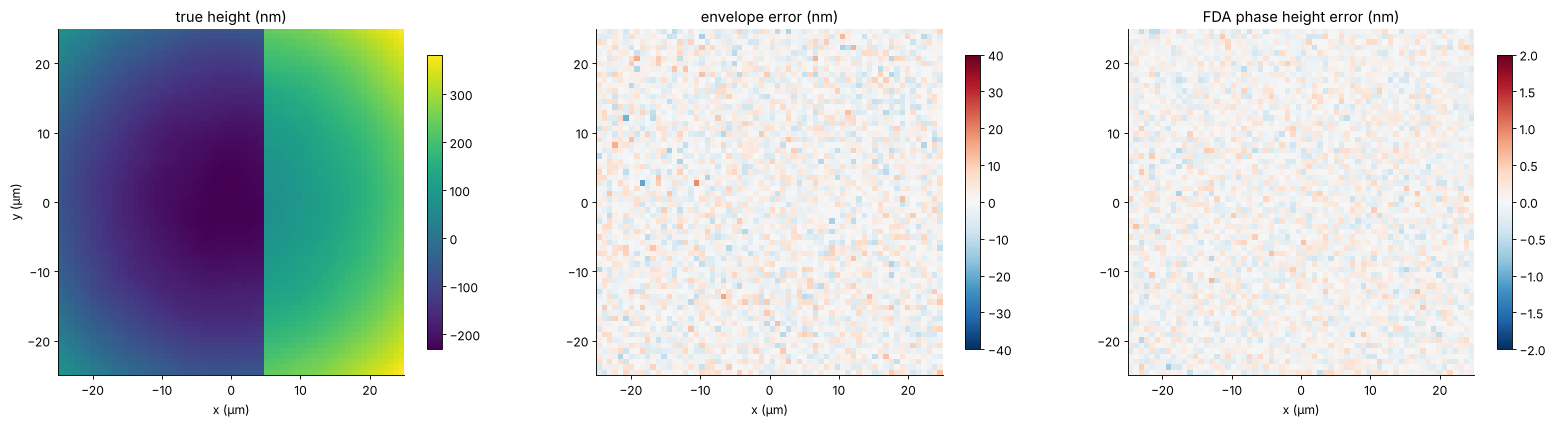

rms error: envelope 4.3 nm, FDA coherence 3.7 nm, FDA phase 0.18 nm (roughness 2.0 nm rms)


In [6]:
n_px = 64
xp = np.linspace(-25, 25, n_px)                   # µm in the object
X, Y = np.meshgrid(xp, xp)
rough = np.real(np.fft.ifft2(np.fft.fft2(rng.standard_normal((n_px, n_px)))
                             * np.exp(-(np.fft.fftfreq(n_px)[:, None]**2
                                        + np.fft.fftfreq(n_px)[None, :]**2)/0.01)))
rough *= 0.002/rough.std()
H = -0.4*(1 - (X**2 + Y**2)/40**2) + np.where(X > 5, 0.3, 0.0) + rough
H -= H.mean()
t0 = time.time()
I = csi.correlogram(z_m, k_m, S_m, H, NA=0.3, reflectance=-0.2)
I += 0.015*fringe_contrast*rng.standard_normal(I.shape)
h_env = csi.envelope_peak(z_m, I)
h_coh, h_ph, _ = csi.fda(z_m, I, K_band, phase_gap=np.pi)
print("{} correlograms of {} frames: {:.1f} s".format(n_px**2, len(z_m), time.time() - t0))
fig, axs = plt.subplots(1, 3, figsize=(20, 5.2), layout="constrained")
for ax, data, t, lim in ((axs[0], H*1e3, "true height (nm)", None),
                         (axs[1], (h_env - H)*1e3, "envelope error (nm)", 40),
                         (axs[2], (h_ph - H)*1e3, "FDA phase height error (nm)", 2)):
    im = ax.imshow(data, origin="lower", extent=(-25, 25, -25, 25), cmap="RdBu_r" if lim else "viridis",
                   vmin=-lim if lim else None, vmax=lim if lim else None)
    ax.set_title(t)
    ax.set_xlabel("x (µm)")
    plt.colorbar(im, ax=ax, shrink=0.85)
axs[0].set_ylabel("y (µm)")
plt.show()
print("rms error: envelope {:.1f} nm, FDA coherence {:.1f} nm, FDA phase {:.2f} nm "
      "(roughness 2.0 nm rms)".format(np.std(h_env - H)*1e3, np.std(h_coh - H)*1e3,
                                     np.std(h_ph - H)*1e3))

The envelope map has a noise of 4 nm, twice the roughness, which it
cannot resolve; the phase map has 0.2 nm and shows the roughness in
full. Envelope evaluation is the choice for rough surfaces and steep
slopes, where the phase is not defined; for polished surfaces the phase
is. (Each pixel is computed as if the surface were flat around it; the
lateral effects of section 7
are left out here.)

## 5. Dissimilar materials

The phase height contains $-\arg r_S/(2k)$. A surface of one material only
shifts all heights by the same amount, but where the material changes,
say an aluminium pad on silicon, the phase on reflection changes too:
the phase height jumps by $-\Delta\arg r_S/(2k)$ although the surface is
flat. The envelope is not affected (to first order). Below the step
measured on flat surfaces of different materials, relative to glass
(indices near 570 nm, rounded; `csi.film_reflectance()`).

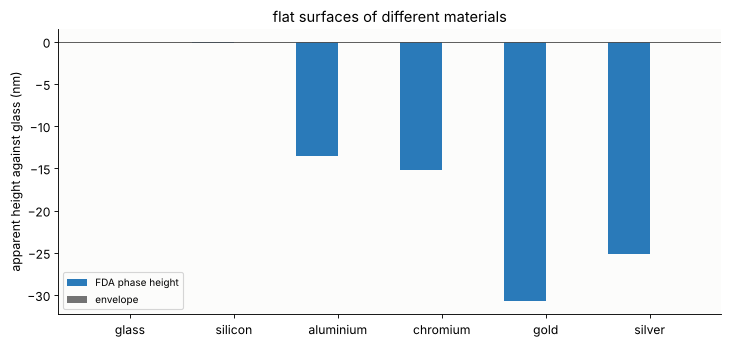

glass     : phase    0.0 nm, envelope   0.0 nm, normal incidence formula   -0.0 nm
silicon   : phase   -0.2 nm, envelope   0.0 nm, normal incidence formula   -0.2 nm
aluminium : phase  -13.5 nm, envelope   0.0 nm, normal incidence formula  -13.2 nm
chromium  : phase  -15.2 nm, envelope   0.0 nm, normal incidence formula  -14.8 nm
gold      : phase  -30.8 nm, envelope   0.0 nm, normal incidence formula  -30.0 nm
silver    : phase  -25.2 nm, envelope   0.0 nm, normal incidence formula  -24.6 nm


In [7]:
materials = {"glass": 1.52, "silicon": el.silicon_index(0.57), "aluminium": 0.96 + 6.69j,
             "chromium": 3.1 + 3.3j, "gold": 0.31 + 2.88j, "silver": 0.12 + 3.6j}
z_f = np.arange(-2, 2, 0.02)
ref_ph = None
rows = []
for name, n in materials.items():
    Ii = csi.correlogram(z_f, k_m, S_m, 0.0, NA=0.3, reflectance=csi.film_reflectance([], n))
    hc, hp, K0 = csi.fda(z_f, Ii, K_band, phase_gap=np.pi)   # calibrated on glass
    he = csi.envelope_peak(z_f, Ii)
    if ref_ph is None:
        ref_ph, ref_env = hp, he
    r0 = (1 - n)/(1 + n)
    rows.append((name, (hp - ref_ph)*1e3, (he - ref_env)*1e3,
                 -np.angle(r0/(1 - 1.52)*(1 + 1.52))/(2*k0)*1e3))
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
names = [r[0] for r in rows]
ax.bar(np.arange(len(rows)) - 0.2, [r[1] for r in rows], 0.4, color=BLUE, label="FDA phase height")
ax.bar(np.arange(len(rows)) + 0.2, [r[2] for r in rows], 0.4, color=GREY, label="envelope")
ax.set_xticks(np.arange(len(rows)), names)
ax.set_ylabel("apparent height against glass (nm)")
ax.axhline(0, color="0.3", lw=0.8)
ax.legend(fontsize=9)
ax.set_title("flat surfaces of different materials")
plt.show()
for name, a, b, c in rows:
    print("{:10s}: phase {:6.1f} nm, envelope {:5.1f} nm, normal incidence formula {:6.1f} nm"
          .format(name, a, b, c))

Metals appear 10 to 30 nm lower than glass in the phase height, the same
as the normal incidence formula $-\Delta\arg r/(2k_0)$. The envelope is
hardly affected, but too noisy to resolve such offsets anyway. Measuring
a step between materials therefore needs the optical constants of both
(from ellipsometry, notebook 135) or a reference of each material;
coating the part with a thin metal layer is the brute force
alternative.

## 6. Transparent films

A transparent film reflects at its top and at its bottom. When the film
is thicker than the coherence length, the correlogram has two envelopes,
at the top surface and at the optical thickness $n_g d$ below (the group
index, as in OCT); their distance gives the thickness. A thinner film
merges them, and $\arg r_S$ now depends on $k$: the FDA phase is no
longer a straight line, its slope (the coherence height) and phase are
both biased, the **thin film effect**. Below a SiO₂ film on silicon with
its top surface always at $h = 0$.

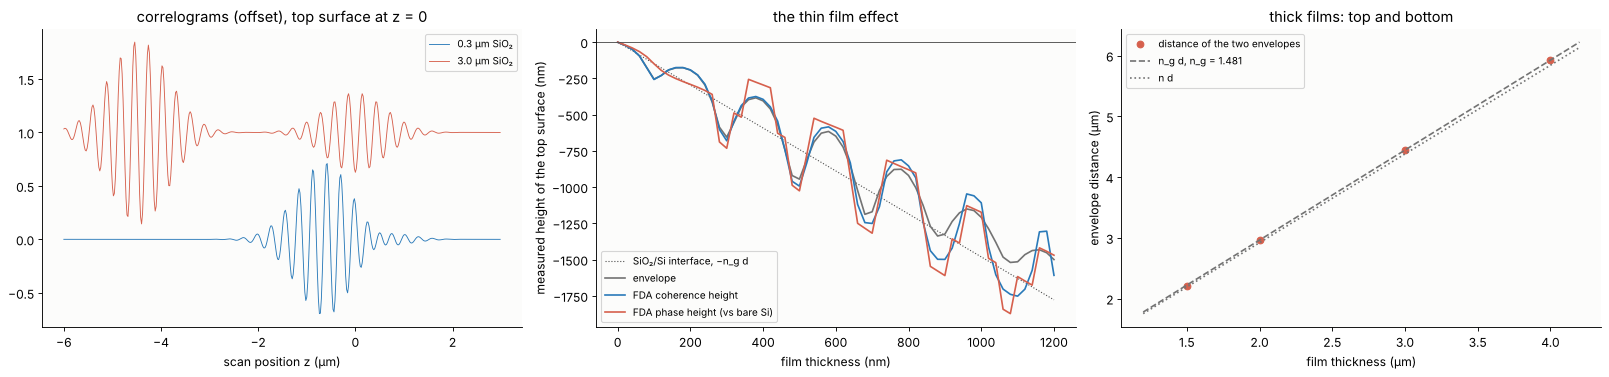

In [8]:
thick = np.array([0.0, 0.1, 0.2, 0.4, 0.6, 1.0, 1.5, 2.0, 3.0])
k_f = k_m[(2*np.pi/k_m >= 0.42) & (2*np.pi/k_m <= 0.78)]
S_f = csi.led_spectrum(k_f, 0.57, 0.10)
z_t = np.arange(-6, 3, 0.02)
K_bf = (2*k_f.min()*0.9, 2*k_f.max()*1.02)
fig, axs = plt.subplots(1, 3, figsize=(20, 4.6), layout="constrained")
for d, c in ((0.3, BLUE), (3.0, RED)):
    Ii = csi.correlogram(z_t, k_f, S_f, 0.0, NA=0.2,
                         reflectance=csi.film_reflectance([(el.sio2_index, d)], el.silicon_index))
    axs[0].plot(z_t, Ii - Ii.mean() + (0 if d < 1 else 1.0), color=c, lw=0.8,
                label="{:.1f} µm SiO₂".format(d))
axs[0].set_xlabel("scan position z (µm)")
axs[0].set_title("correlograms (offset), top surface at z = 0")
axs[0].legend(fontsize=9)
dense = np.linspace(0.0, 1.2, 61)
e_env, e_coh, e_ph = [], [], []
for d in dense:
    refl = csi.film_reflectance([(el.sio2_index, d)] if d > 0 else [], el.silicon_index)
    Ii = csi.correlogram(z_t, k_f, S_f, 0.0, NA=0.2, reflectance=refl)
    hc, hp, _ = csi.fda(z_t, Ii, K_bf, phase_gap=np.pi)
    e_env.append(csi.envelope_peak(z_t, Ii))
    e_coh.append(hc)
    e_ph.append(hp)
base = e_ph[0]
lam_f = 2*np.pi/k_f
n_ph = el.sio2_index(lam_f).real
n_g = n_ph - lam_f*np.gradient(n_ph, lam_f)
ng0 = np.sum(S_f*n_g)/np.sum(S_f)
axs[1].plot(dense*1e3, -ng0*dense*1e3, color="0.3", ls=":", lw=1.0, label="SiO₂/Si interface, −n_g d")
axs[1].plot(dense*1e3, np.array(e_env)*1e3, color=GREY, label="envelope")
axs[1].plot(dense*1e3, np.array(e_coh)*1e3, color=BLUE, label="FDA coherence height")
axs[1].plot(dense*1e3, (np.array(e_ph) - base)*1e3, color=RED, label="FDA phase height (vs bare Si)")
axs[1].axhline(0, color="0.3", lw=0.8)
axs[1].set_xlabel("film thickness (nm)")
axs[1].set_ylabel("measured height of the top surface (nm)")
axs[1].set_title("the thin film effect")
axs[1].legend(fontsize=9)
# thick films: two envelopes
z_l = np.arange(-8, 1, 0.02)
gaps = []
for d in (1.5, 2.0, 3.0, 4.0):
    Ii = csi.correlogram(z_l, k_f, S_f, 0.0, NA=0.2,
                         reflectance=csi.film_reflectance([(el.sio2_index, d)], el.silicon_index))
    env = csi.envelope(Ii)
    from scipy.signal import find_peaks
    pk, _ = find_peaks(env, height=0.3*env.max(), distance=40)
    top2 = np.sort(z_l[pk[np.argsort(env[pk])[-2:]]])
    gaps.append(top2[1] - top2[0])
axs[2].plot([1.5, 2.0, 3.0, 4.0], gaps, "o", color=RED, label="distance of the two envelopes")
dd = np.linspace(1.2, 4.2, 10)
axs[2].plot(dd, ng0*dd, color=GREY, ls="--", label="n_g d, n_g = {:.3f}".format(ng0))
axs[2].plot(dd, 1.46*dd, color=GREY, ls=":", label="n d")
axs[2].set_xlabel("film thickness (µm)")
axs[2].set_ylabel("envelope distance (µm)")
axs[2].set_title("thick films: top and bottom")
axs[2].legend(fontsize=9)
plt.show()

The top surface is at $h = 0$ for all films, but no evaluation finds
it. The silicon below reflects about twice as strongly as the top of the
oxide, so once the film is thicker than the coherence length the
measurements follow the buried interface at $-n_g d$, jumping between
fringe orders on the way. Below about 300 nm the two reflections merge
into one correlogram and the heights land anywhere, even below the
buried interface: errors of hundreds of nanometres from a transparent
film of a few hundred nanometres. For thick films the two envelopes
separate (right) and their distance is the optical thickness with the
group index, as in OCT, 1.5 % more than with the phase index.

The thin film effect becomes a measurement once the film is modelled:
the Fourier transform of the correlogram, amplitude and phase over $K$,
is the spectrum times $r_S(k)$ of the stack (the "helical complex
field" of de Groot and Colonna de Lega). A least squares fit of the
thickness and the height of the top surface to it recovers both from one
correlogram, also for films far thinner than the coherence length.

In [9]:
from scipy.optimize import least_squares

z_s = np.arange(-3, 3, 0.02)
K_fit = np.linspace(2*k_f.min()*0.98, 2*k_f.max()*0.98, 48)
c_fit = np.ones(1)


def signature(d, h, NA=0.2):
    refl = csi.film_reflectance([(el.sio2_index, d)] if d > 1e-4 else [], el.silicon_index)
    return csi.fourier_signal(z_s, csi.correlogram(z_s, k_f, S_f, h, NA=NA, reflectance=refl),
                              K_fit)


def fit_film(F_meas, d0):
    def res(p):
        F = p[2]*signature(p[0], p[1])
        return np.concatenate([(F - F_meas).real, (F - F_meas).imag])/np.abs(F_meas).max()
    r = least_squares(res, (d0, 0.0, 1.0), bounds=([0.0, -1.0, 0.1], [2.0, 1.0, 10.0]))
    return r.x


print("film (nm)   fit thickness (nm)   fit top height (nm)")
for d_true, h_top in ((0.050, 0.120), (0.150, -0.080), (0.400, 0.030), (0.800, 0.0)):
    Ii = csi.correlogram(z_s, k_f, S_f, h_top, NA=0.2,
                         reflectance=csi.film_reflectance([(el.sio2_index, d_true)], el.silicon_index))
    Ii = Ii + 0.003*rng.standard_normal(Ii.shape)
    F_meas = csi.fourier_signal(z_s, Ii, K_fit)
    # a coarse search over the thickness avoids the local minima of the periodic signature
    cands = [fit_film(F_meas, d0) for d0 in np.arange(0.02, 1.2, 0.1)]
    best = min(cands, key=lambda p: np.sum(np.abs(p[2]*signature(p[0], p[1]) - F_meas)**2))
    print("{:8.0f}   {:14.1f}   {:20.1f}   (true top {:.0f} nm)".format(d_true*1e3, best[0]*1e3,
                                                                       best[1]*1e3, h_top*1e3))

film (nm)   fit thickness (nm)   fit top height (nm)


      50             50.4                  120.5   (true top 120 nm)


     150            149.8                  -80.3   (true top -80 nm)


     400            400.1                   30.1   (true top 30 nm)


     800            800.0                    0.1   (true top 0 nm)


The model fit finds thickness and top surface to about a nanometre,
down to 50 nm films whose two reflections overlap completely. It needs
the optical constants of film and substrate and a good model of the
instrument (spectrum, NA), which is exactly what ellipsometry provides
and needs too (notebook 135, ellipsometry).

## 7. Steps and the batwing artefact

Everything so far assumed that each pixel sees a flat surface. At a step
the objective's point spread function mixes light from both levels. When
the step is lower than the coherence length, the two contributions
interfere within one envelope; for a step of about $\lambda/4$ they are
out of phase, the fringe contrast collapses at the edge and the envelope
of the mixed correlogram moves, which bends the measured profile up on
one side of the edge and down on the other: the **batwing** (Harasaki and
Wyant 2000). `csi.profile_scan()` simulates the correlograms of a line
profile with scalar imaging, illumination angles up to the NA and the
exact angular spectrum of the reflected field.

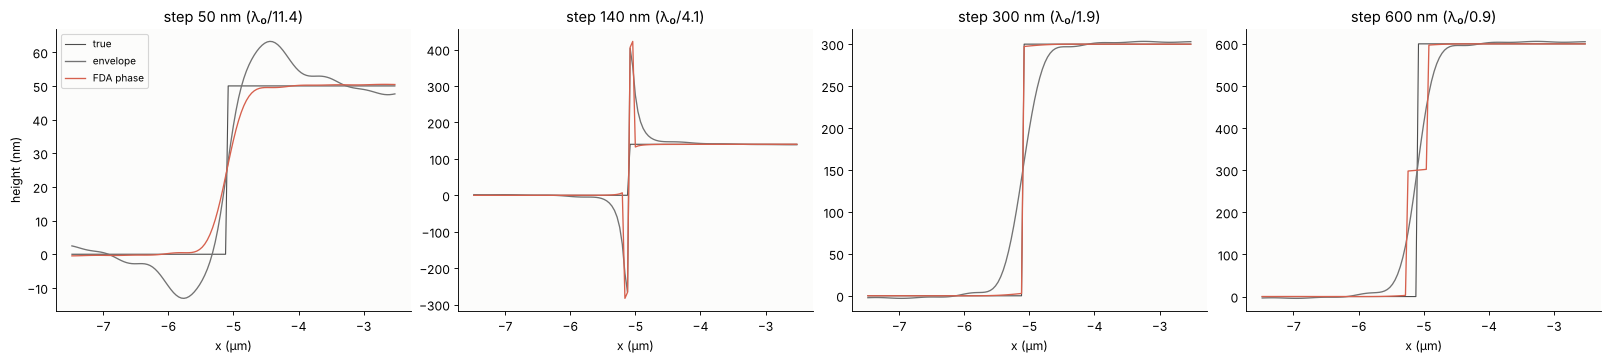

profile scans: 1.8 s
step  50 nm: envelope overshoot   +13 nm on the top,   -13 nm at the foot
step 140 nm: envelope overshoot  +263 nm on the top,  -266 nm at the foot
step 300 nm: envelope overshoot    +3 nm on the top,    -3 nm at the foot
step 600 nm: envelope overshoot    +6 nm on the top,    -4 nm at the foot


In [10]:
x = np.arange(512)*0.04 - 10.24
z_b = np.arange(-1.5, 2.0, 0.02)
k_b, S_b = k_m[::2], S_m[::2]
steps = (0.05, 0.14, 0.30, 0.60)
fig, axs = plt.subplots(1, len(steps), figsize=(20, 4.4), layout="constrained", sharey=False)
t0 = time.time()
peaks = []
for ax, hs in zip(axs, steps):
    h_prof = np.where(np.abs(x) < 5.12, hs, 0.0)
    P = csi.profile_scan(x, h_prof, z_b, k_b, S_b, NA=0.4, n_illumination=7, reflectance=-0.2)
    he = csi.envelope_peak(z_b, P.T, "parabola")
    _, hp, _ = csi.fda(z_b, P.T, (2*k_b.min()*0.88, 2*k_b.max()*1.02), phase_gap=np.pi)
    sel = (x > -7.5) & (x < -2.5)
    ax.plot(x[sel], h_prof[sel]*1e3, color="0.3", lw=1.0, label="true")
    ax.plot(x[sel], he[sel]*1e3, color=GREY, lw=1.2, label="envelope")
    ax.plot(x[sel], hp[sel]*1e3, color=RED, lw=1.2, label="FDA phase")
    ax.set_title("step {:.0f} nm (λ₀/{:.1f})".format(hs*1e3, 0.57/hs))
    ax.set_xlabel("x (µm)")
    peaks.append((np.max(he[sel]) - hs, np.min(he[sel])))
axs[0].set_ylabel("height (nm)")
axs[0].legend(fontsize=9)
plt.show()
print("profile scans: {:.1f} s".format(time.time() - t0))
for hs, (over, under) in zip(steps, peaks):
    print("step {:3.0f} nm: envelope overshoot {:+5.0f} nm on the top, {:+5.0f} nm at the foot"
          .format(hs*1e3, over*1e3, under*1e3))

The envelope profile overshoots on both sides of the edge. For the step
near $\lambda/4$ (140 nm) the overshoot is larger than the step itself:
the light from the two levels arrives in antiphase, the fringe contrast
at the edge collapses and what is left of the correlogram sits far from
either level. The phase height inherits the error there, because its
fringe order comes from the coherence height. The 50 nm step shows a
milder version, the 300 and 600 nm steps, whose two levels have
separate envelopes, hardly any; the phase follows them sharply, but
the 600 nm step has a pixel with the wrong fringe order right at the
edge. Instruments therefore flag pixels near edges, and step height
standards are evaluated on wide plateaus away from them.

## Summary

- The correlogram of a broadband source has an envelope of
  $2\ln2\,\lambda_0^2/(\pi\Delta\lambda)$, about a micrometre; its peak
  gives the height without ambiguity, the fringe phase refines it.
- Frequency domain analysis gives a coherence height from the slope of
  the spectral phase and a phase height that is about twenty times less
  noisy, provided the coherence height picks the right
  fringe order.
- High NA objectives lengthen the fringes by
  $\langle\cos\theta\rangle \approx 1 - \mathrm{NA}^2/4$; FDA measures the
  actual fringe frequency, phase evaluation with a nominal wavelength must
  be corrected.
- The phase on reflection shifts metals by 10 to 30 nm against glass in
  the phase height; transparent films bias both envelope and phase by
  hundreds of nanometres (thin film effect) unless modelled, and then
  their thickness and the top surface can be fitted from the spectral
  signature.
- At steps lower than the coherence length the envelope overshoots
  (batwings), by more than the step near $\lambda/4$.

## References

- P. de Groot, "Coherence scanning interferometry", in R. Leach (ed.),
  *Optical Measurement of Surface Topography*, Springer (2011).
- P. de Groot and L. Deck, "Surface profiling by analysis of white-light
  interferograms in the spatial frequency domain", J. Mod. Opt. 42, 389
  (1995).
- P. de Groot, X. Colonna de Lega, J. Kramer and M. Turzhitsky,
  "Determination of fringe order in white-light interference
  microscopy", Appl. Opt. 41, 4571 (2002).
- C. J. R. Sheppard and K. G. Larkin, "Effect of numerical aperture on
  interference fringe spacing", Appl. Opt. 34, 4731 (1995).
- A. Harasaki and J. C. Wyant, "Fringe modulation skewing effect in
  white-light vertical scanning interferometry", Appl. Opt. 39, 2101
  (2000).
- S.-W. Kim and G.-H. Kim, "Thickness-profile measurement of transparent
  thin-film layers by white-light scanning interferometry", Appl. Opt.
  38, 5968 (1999).
- P. de Groot and X. Colonna de Lega, "Signal modeling for low-coherence
  height-scanning interference microscopy", Appl. Opt. 43, 4821 (2004).

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 170 s
